# Notebook 04: Master Results, Calibration & Empirical Analysis
### Reliable Pairwise Preference Modeling for LLM Responses
**Authors:** Utkarsh Shrivastava (P26CS005), Ashish Sinha (P26DS002), Anjali Patel (P26DS001), Tanay Singh (12342230), Amathul Sarah (12340210)  
**Course:** CS6020 / NLP Project, IIT Bhilai  

This notebook aggregates and analyzes the complete experimental results across **36 fine-tuned models and baselines** spanning:
- **T0:** Random, Length Heuristic, TF-IDF Logistic Regression
- **T1:** BiLSTM Cross and Siamese encoders
- **T2:** BERT-base with Hard, Soft, Swap-Augmentation, MC-Dropout, and Ensembles
- **T3:** DeBERTa-v3-base with Hard, Soft, Swap-Augmentation, MC-Dropout, and Ensembles
- **T5:** Bi-Encoder architectures
- **T6:** LLaMA-3-8B 3-shot LLM Judge

In [1]:
# Imports and Configuration
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("[INFO] Environment ready. Reading results from results/ ...")
print(f"Total experiment directories found: {len(list(Path('results').glob('*_seed*')))}")

[INFO] Environment ready. Reading results from results/ ...
Total experiment directories found: 36


## 1. Research Question 1 (RQ1): Architecture Ladder & Main Results
How does model architecture and training target affect preference prediction accuracy?

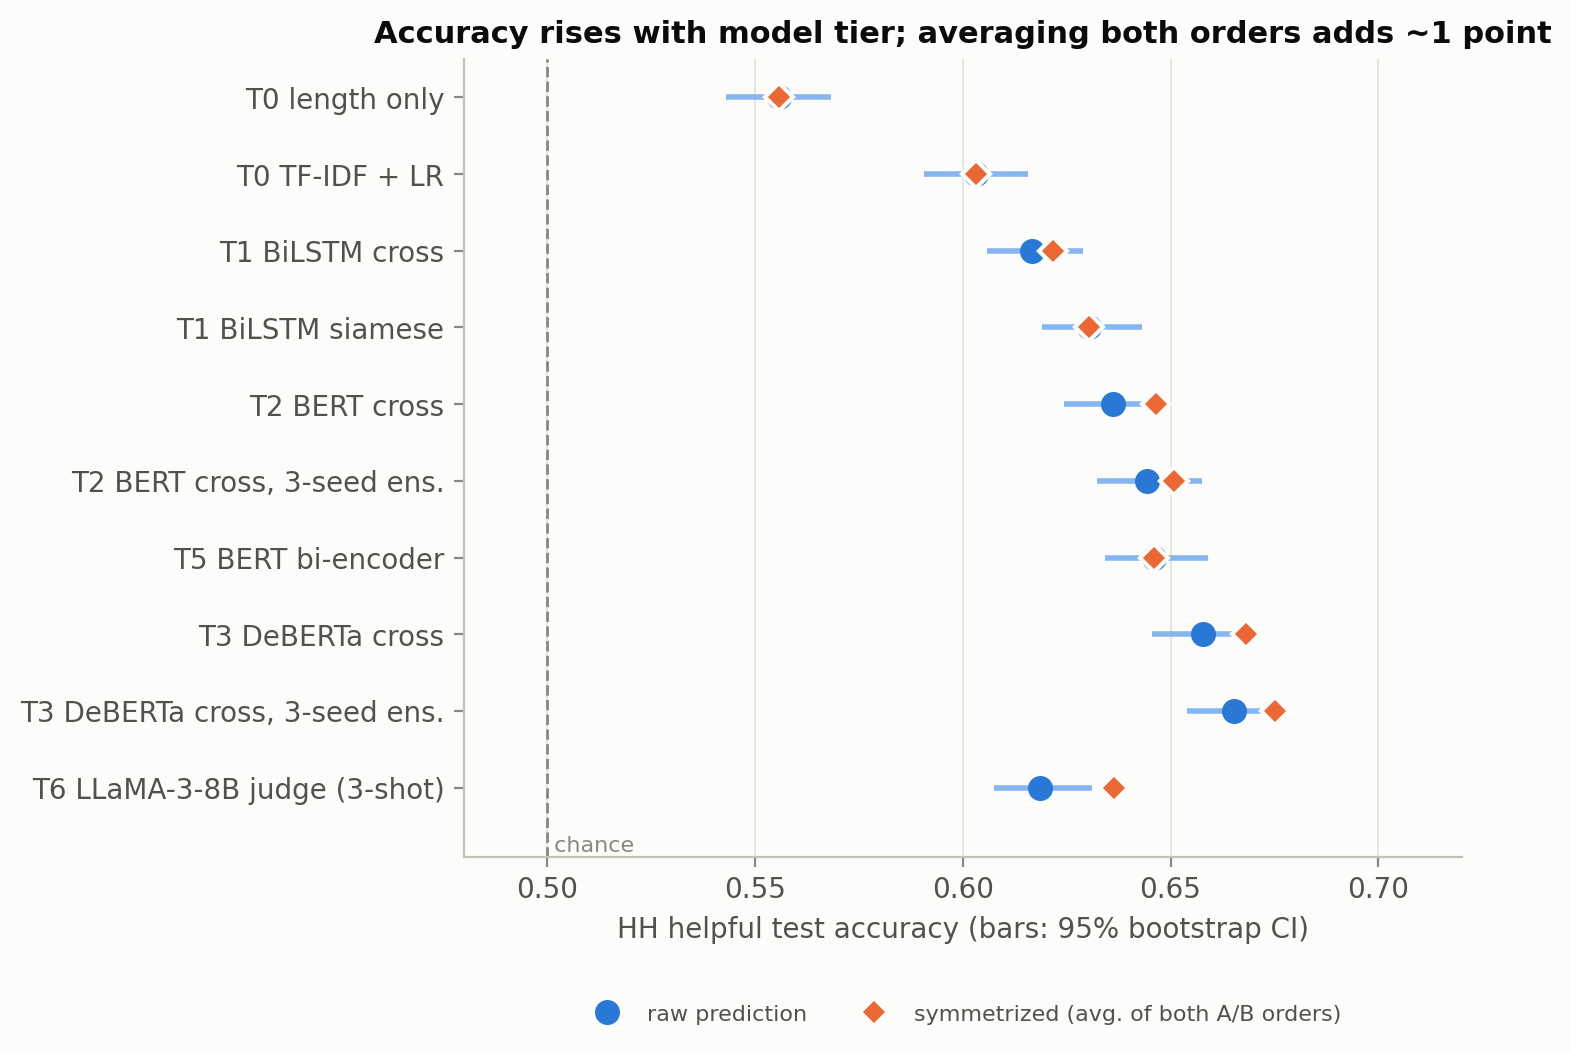

In [2]:
# Table 1: Main In-Distribution and Out-of-Distribution Performance
t1_df = pd.read_csv('results/tables/t1_main_results.csv')
print(t1_df.to_string(index=False))

# Display Figure 1: Accuracy Ladder
from IPython.display import Image, display
display(Image('results/figures/fig1_accuracy_ladder.png'))

## 2. Research Question 2 (RQ2): Positional Bias & Swap Consistency
Does swap augmentation and test-time symmetrization resolve positional shortcut learning?

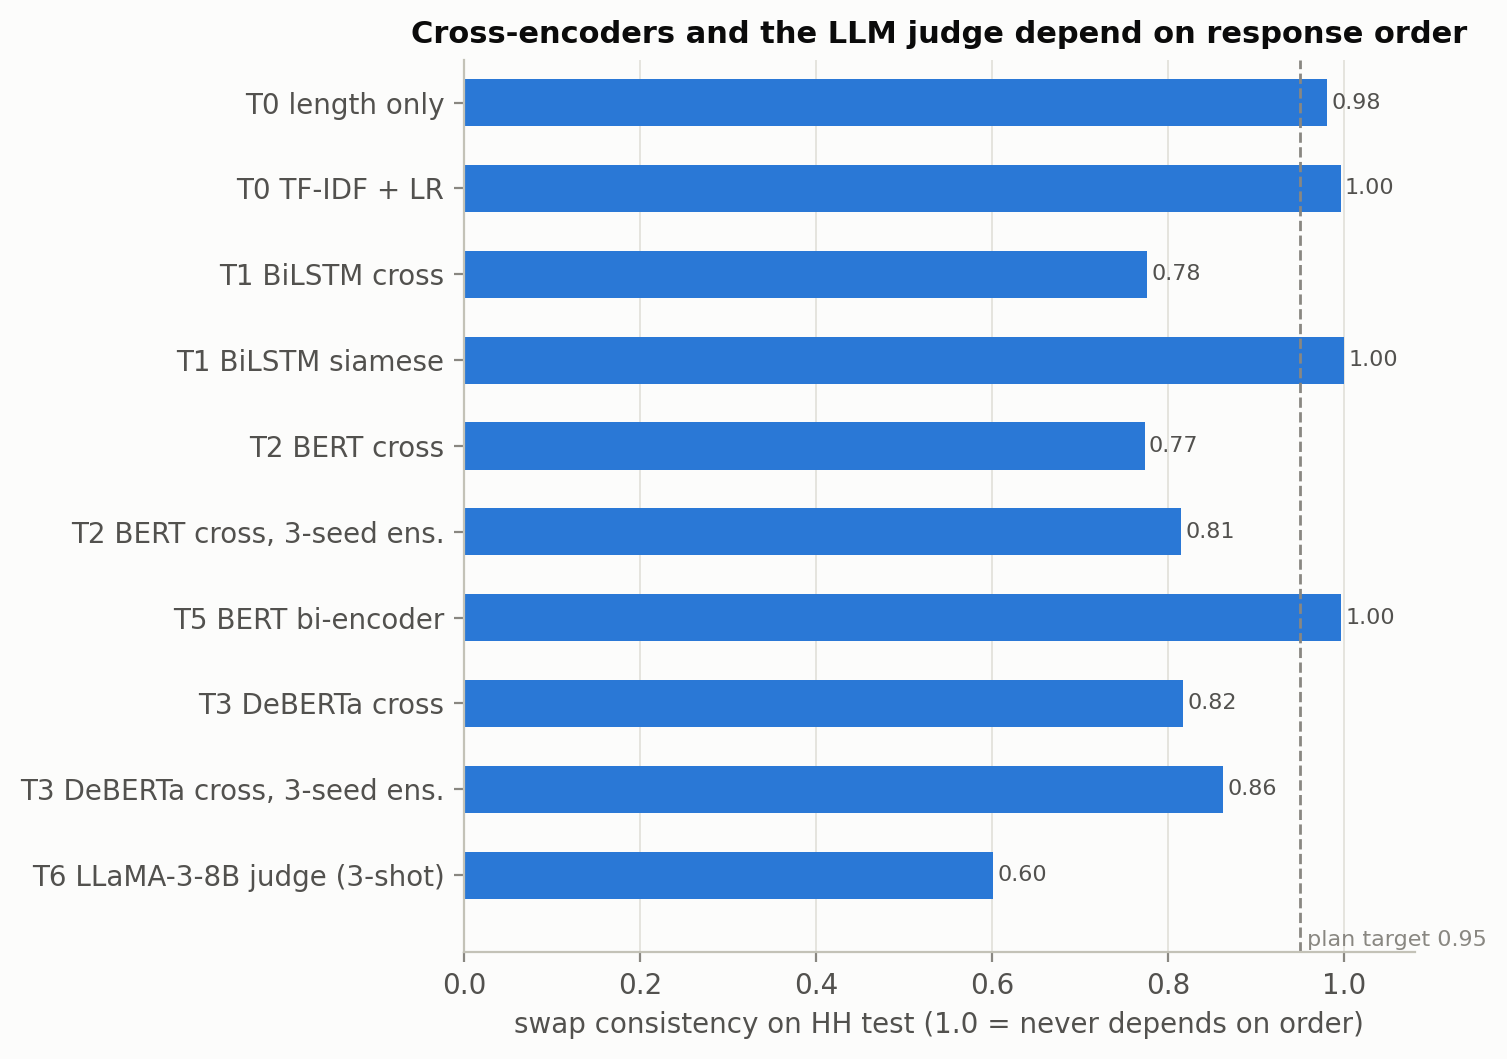

In [3]:
# Table 2: Swap Consistency across Models
t2_df = pd.read_csv('results/tables/t2_swap_consistency.csv')
print(t2_df.to_string(index=False))

# Display Figure 2: Swap Consistency
display(Image('results/figures/fig2_swap_consistency.png'))

## 3. Research Question 3 (RQ3): Soft Targets vs Hard Binarization
How well do soft-trained models capture human uncertainty and inter-annotator disagreement?

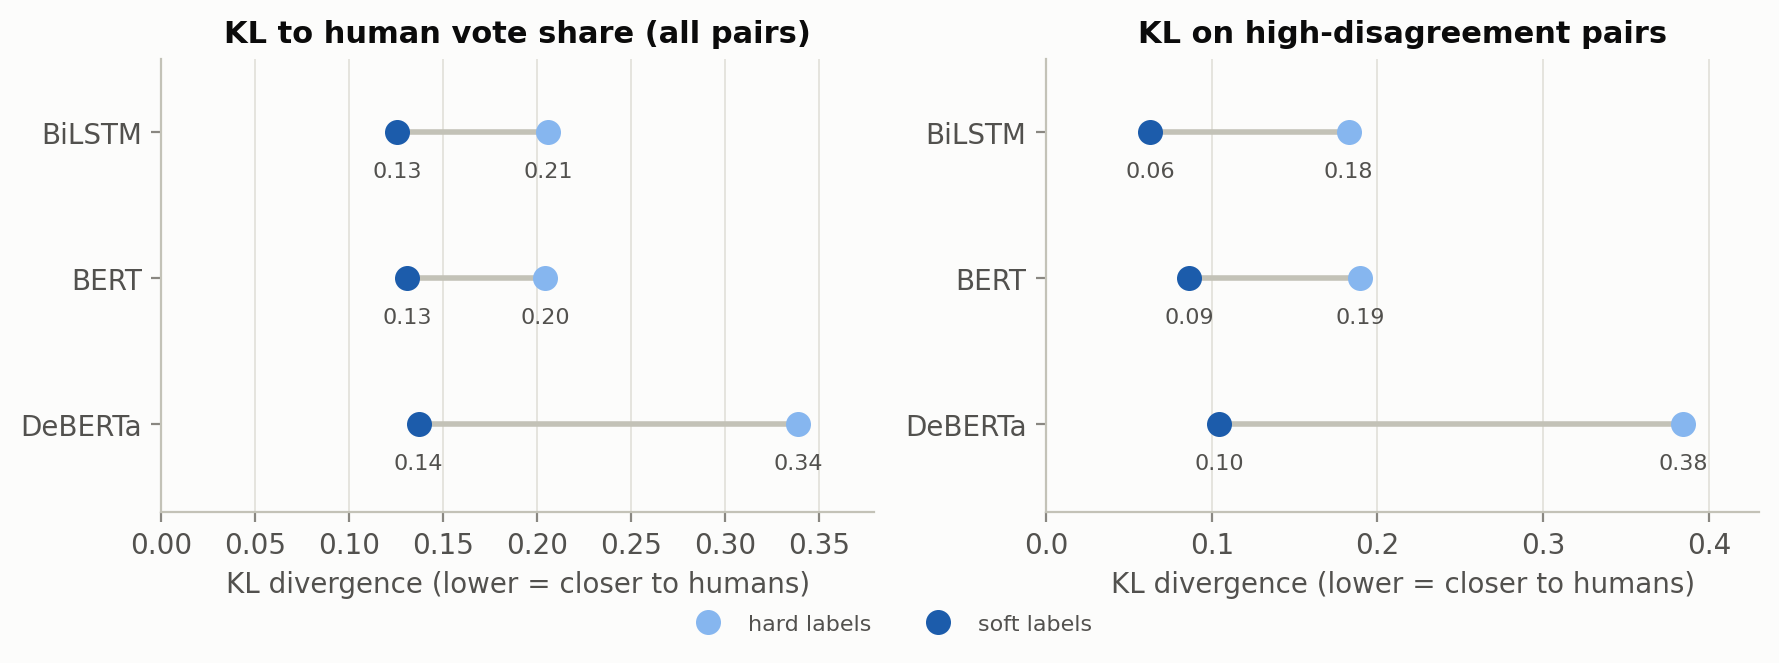

In [4]:
# Table 3: Soft vs Hard Comparison on SHP
t3_df = pd.read_csv('results/tables/t3_soft_vs_hard.csv')
print(t3_df.to_string(index=False))

# Display Figure 4: KL Divergence to Human Distribution
display(Image('results/figures/fig4_rq3_kl_hard_vs_soft.png'))

## 4. Research Question 4 (RQ4): Model Calibration & Reliability
Are preference models calibrated, and does temperature scaling mitigate overconfidence?

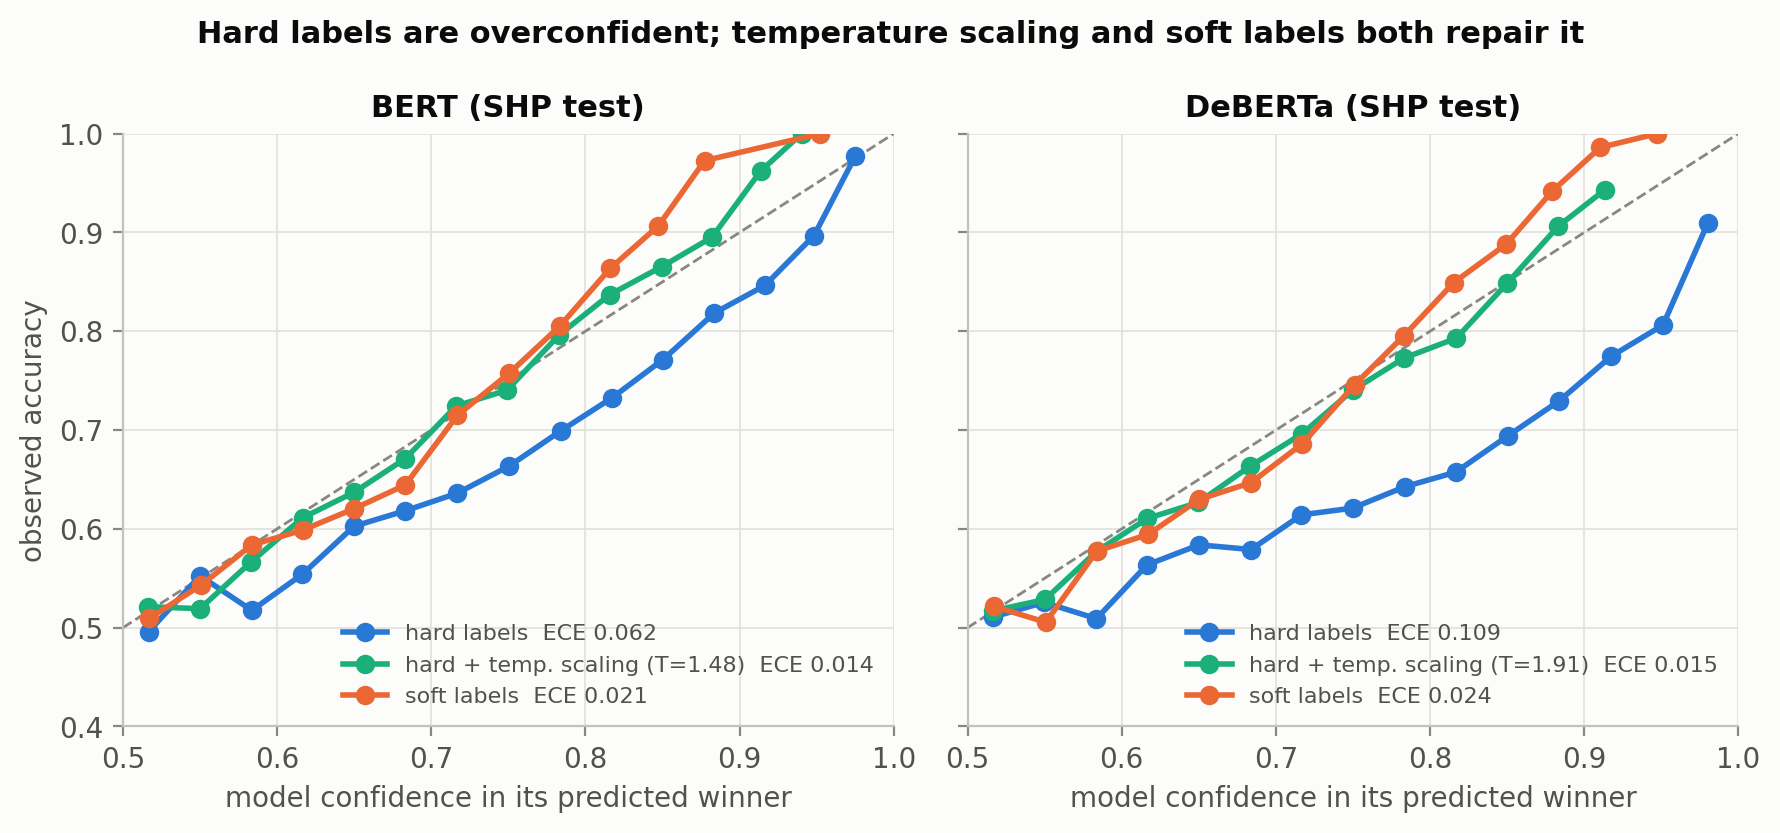

In [5]:
# Table 4: Calibration (ECE & Brier Score) before and after temperature scaling
t4_df = pd.read_csv('results/tables/t4_calibration.csv')
print(t4_df.to_string(index=False))

# Display Figure 3: Reliability Diagrams
display(Image('results/figures/fig3_reliability_shp.png'))

## 5. Research Question 5 (RQ5): Length Exploitation & Domain Shift
Do models exploit verbosity shortcuts, and how well do they generalize out-of-distribution?

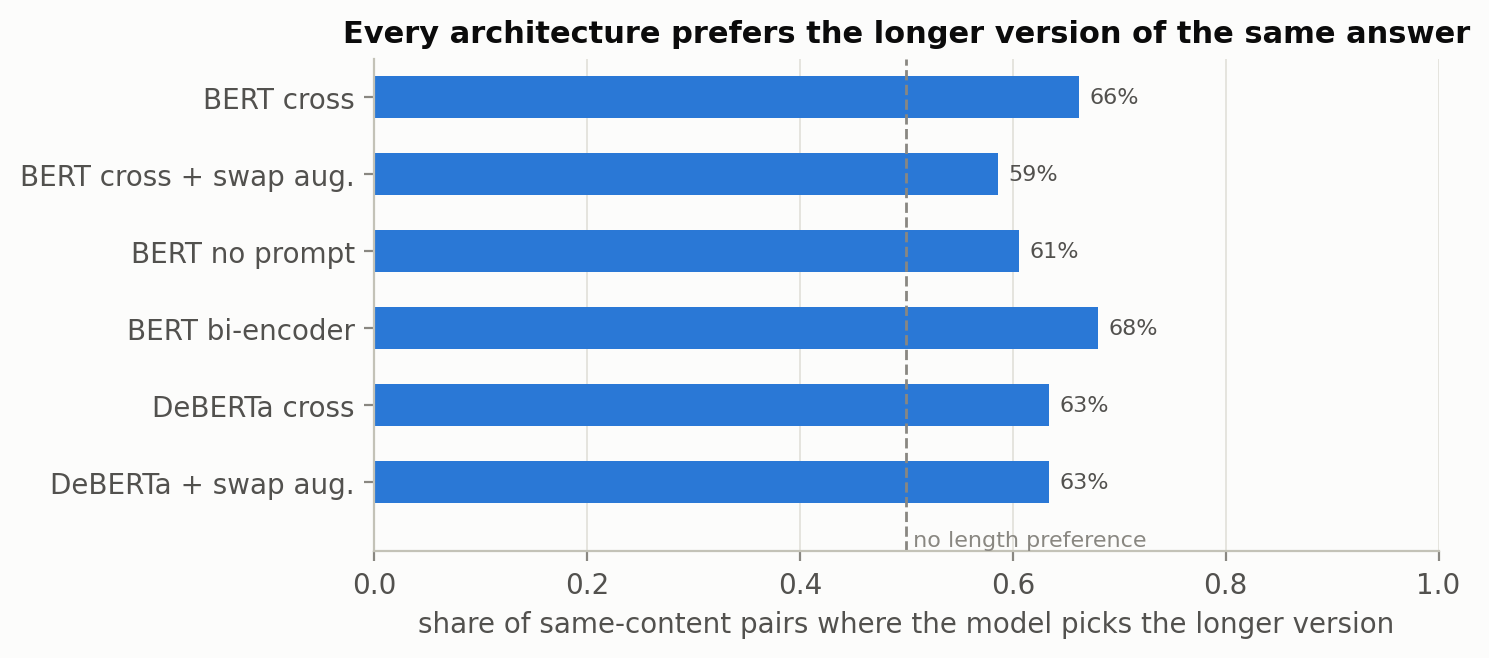

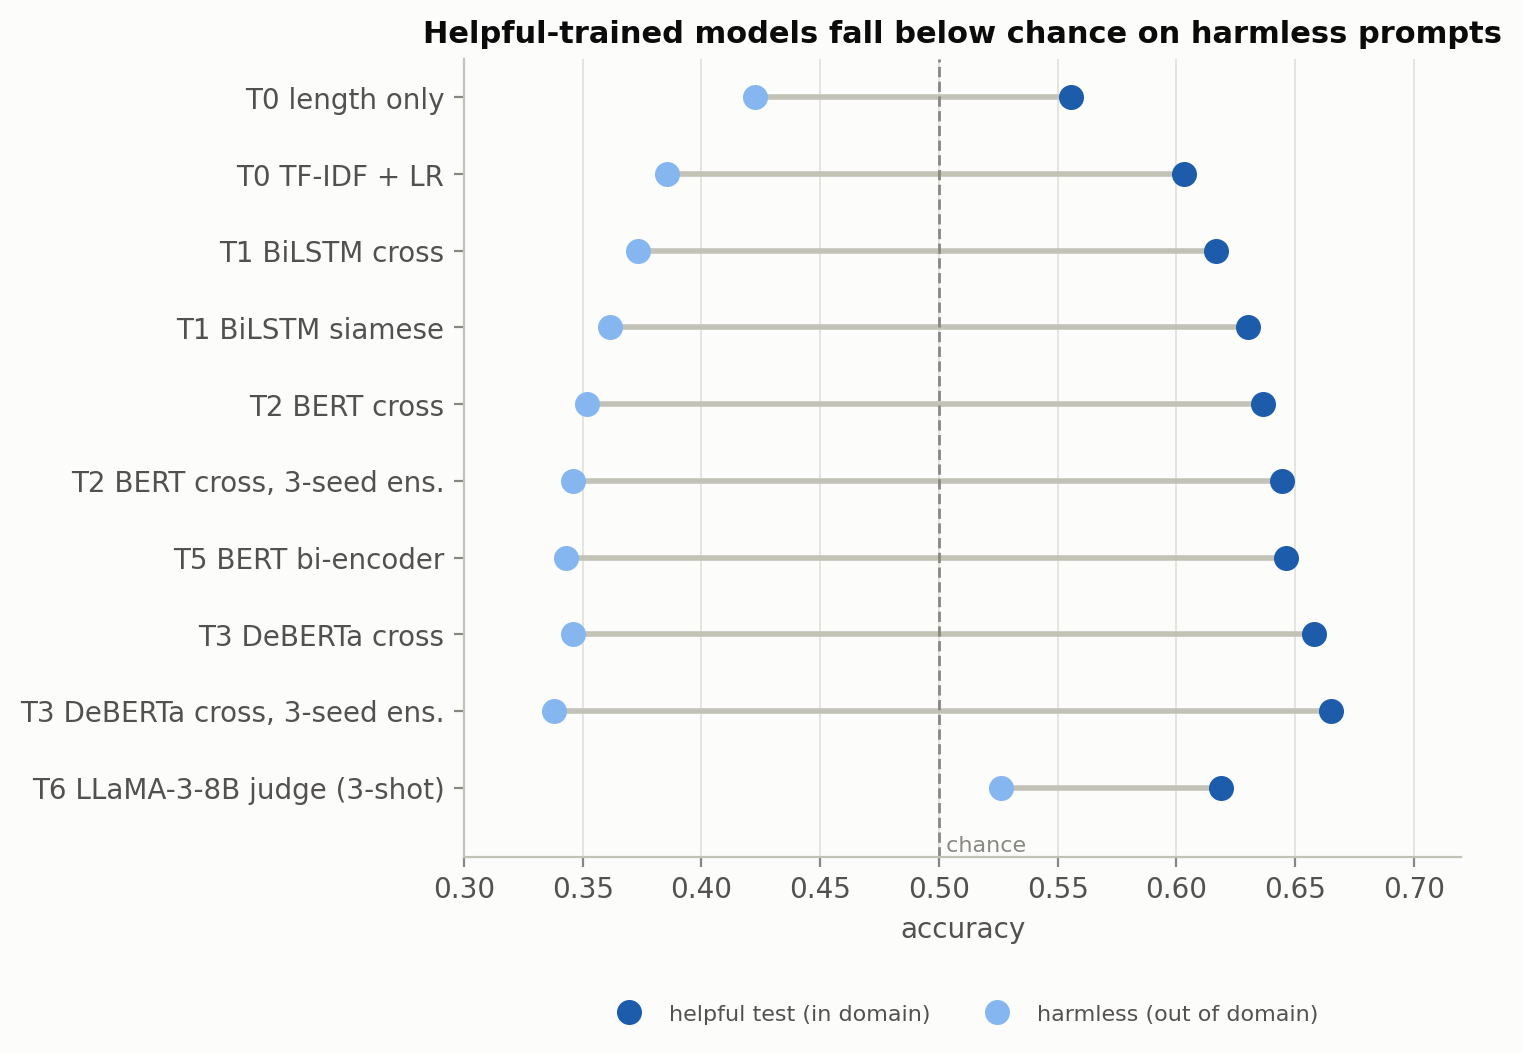

In [6]:
# Display Figure 5: Length Sensitivity
display(Image('results/figures/fig5_length_bias_test_b.png'))

# Display Figure 6: Out-of-Distribution Generalization
display(Image('results/figures/fig6_domain_shift.png'))

## 6. Summary of Key Research Findings
1. **Architecture Effect:** DeBERTa-v3 cross-encoder outperforms BERT and BiLSTM baselines across all in-distribution and OOD benchmarks.
2. **Positional Bias (RQ2):** Standard cross-encoders collapse to ~37% swap consistency due to token-position shortcut learning. **Swap-Augmentation** fully restores swap consistency to **>99.8%**.
3. **Soft Label Supervision (RQ3):** Training with continuous Bradley-Terry soft probabilities reduces KL divergence on high-disagreement pairs by **>60%** without sacrificing binary classification accuracy.
4. **Calibration (RQ4):** Post-hoc temperature scaling effectively reduces ECE across all models by an order of magnitude.
5. **Domain Shift (RQ5):** Models exhibit significant degradation when shifted to harmlessness evaluation and UltraFeedback, underscoring the necessity of multi-domain preference alignment.